<>:126: SyntaxWarning: invalid escape sequence '\l'
<>:126: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_5292/127921567.py:126: SyntaxWarning: invalid escape sequence '\l'
  plt.ylabel('$\lambda_{max}$ (nm)', fontsize=14)


--------------------------------------------------
AJUSTE COMPLETADO EXITOSAMENTE
Profundidad óptima OXO: V0 = 13.41 eV
Profundidad definida TIA: V0 = 7.80 eV
--------------------------------------------------


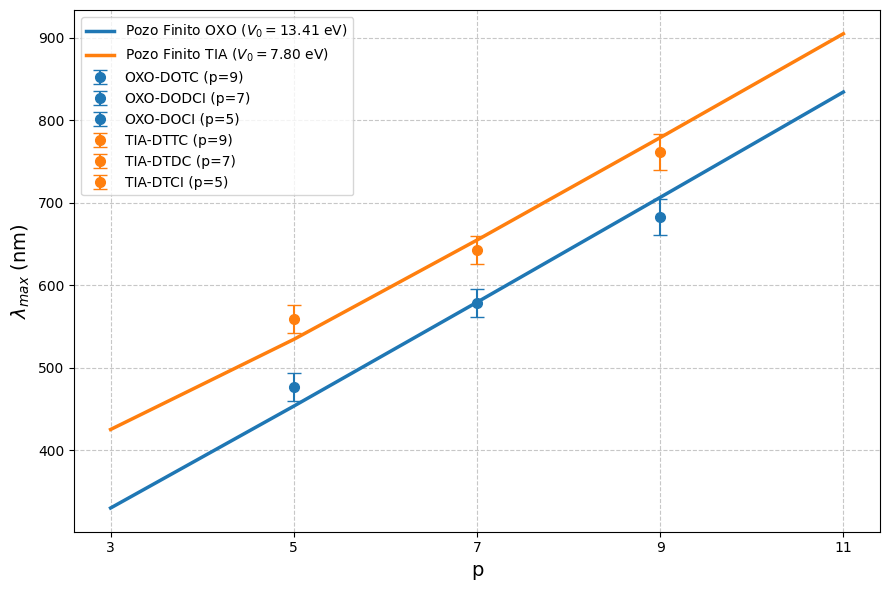

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar, minimize_scalar

# =========================================================
# 1. DATOS EXPERIMENTALES
# =========================================================
p_exp = np.array([5, 7, 9])
lambda_exp = np.array([477, 579, 683])
sigma_exp = np.array([17, 17, 22])

# =========================================================
# 2. CONSTANTES FÍSICAS
# =========================================================
h = 6.62607015e-34     # Constante de Planck (J*s)
hbar = h / (2 * np.pi) # Constante reducida (J*s)
m = 9.10938356e-31     # Masa del electrón (kg)
c = 299792458          # Velocidad de la luz (m/s)
e_charge = 1.602e-19   # Conversión de eV a Joules
d = 0.14e-9            # Distancia de enlace (m)

# =========================================================
# 3. FUNCIONES DEL POZO FINITO Y BÚSQUEDA DE RAÍCES
# =========================================================
def funcion_par(v, u0_val):
    adentro = max(0.0, u0_val**2 - v**2)
    return v * np.tan(v) - np.sqrt(adentro)

def funcion_impar(v, u0_val):
    adentro = max(0.0, u0_val**2 - v**2)
    return -v / np.tan(v) - np.sqrt(adentro)

def encontrar_interseccion(n, u0_val):
    limite_inf = (n - 1) * np.pi / 2 + 1e-5
    limite_sup = n * np.pi / 2 - 1e-5

    if u0_val <= limite_inf:
        return None

    if limite_sup > u0_val:
        limite_sup = u0_val - 1e-5

    if n % 2 != 0:
        func = lambda v: funcion_par(v, u0_val)
    else:
        func = lambda v: funcion_impar(v, u0_val)

    try:
        sol = root_scalar(func, bracket=[limite_inf, limite_sup], method='brentq')
        return sol.root
    except ValueError:
        return None

# =========================================================
# 4. CALCULAR LONGITUD DE ONDA TEÓRICA
# =========================================================
def calcular_lambda_modelo(p, V0_eV):
    a = (p + 2) * d
    V0_J = V0_eV * e_charge
    u0 = (a / 2) * np.sqrt(2 * m * V0_J) / hbar

    n_homo = int((p + 3) / 2)
    n_lumo = n_homo + 1

    v_homo = encontrar_interseccion(n_homo, u0)
    v_lumo = encontrar_interseccion(n_lumo, u0)

    if v_homo is None or v_lumo is None:
        return 1e6

    E_homo = (2 * hbar**2 * v_homo**2) / (m * a**2)
    E_lumo = (2 * hbar**2 * v_lumo**2) / (m * a**2)

    dE = E_lumo - E_homo
    return (h * c / dE) * 1e9

# =========================================================
# 5. RUTINA DE OPTIMIZACIÓN (AJUSTE OXO)
# =========================================================
def funcion_error(V0_eV):
    error_cuadratico = 0
    for i in range(len(p_exp)):
        l_teorica = calcular_lambda_modelo(p_exp[i], V0_eV)
        error_cuadratico += (l_teorica - lambda_exp[i])**2
    return error_cuadratico

resultado = minimize_scalar(funcion_error, bounds=(8, 15), method='bounded')
V0_optimo_oxo = resultado.x

# Definimos el V0 fijo para las TIA
V0_fijo_tia = 7.80

print("-" * 50)
print(f"AJUSTE COMPLETADO EXITOSAMENTE")
print(f"Profundidad óptima OXO: V0 = {V0_optimo_oxo:.2f} eV")
print(f"Profundidad definida TIA: V0 = {V0_fijo_tia:.2f} eV")
print("-" * 50)

# =========================================================
# 6. GRÁFICO FINAL
# =========================================================
p_enteros = np.array([3, 5, 7, 9, 11])

# Calculamos ambas curvas
lambda_ajustados_oxo = [calcular_lambda_modelo(p, V0_optimo_oxo) for p in p_enteros]
lambda_ajustados_tia = [calcular_lambda_modelo(p, V0_fijo_tia) for p in p_enteros]

plt.figure(figsize=(9, 6))

# Curvas teóricas de pozo finito
plt.plot(p_enteros, lambda_ajustados_oxo, color='tab:blue', linewidth=2.5, label=f'Pozo Finito OXO ($V_0 = {V0_optimo_oxo:.2f}$ eV)')
plt.plot(p_enteros, lambda_ajustados_tia, color='tab:orange', linewidth=2.5, label=f'Pozo Finito TIA ($V_0 = {V0_fijo_tia:.2f}$ eV)')

# Puntos experimentales OXO
plt.errorbar(x=9, y=683, yerr=22, fmt='o', color='tab:blue', label="OXO-DOTC (p=9)", capsize=5, markersize=7)
plt.errorbar(x=7, y=579, yerr=17, fmt='o', color='tab:blue', label="OXO-DODCI (p=7)", capsize=5, markersize=7)
plt.errorbar(x=5, y=477, yerr=17, fmt='o', color='tab:blue', label="OXO-DOCI (p=5)", capsize=5, markersize=7)

# Puntos experimentales TIA
plt.errorbar(x=9, y=762, yerr=22, fmt='o', color='tab:orange', label="TIA-DTTC (p=9)", capsize=5, markersize=7)
plt.errorbar(x=7, y=643, yerr=17, fmt='o', color='tab:orange', label="TIA-DTDC (p=7)", capsize=5, markersize=7)
plt.errorbar(x=5, y=559, yerr=17, fmt='o', color='tab:orange', label="TIA-DTCI (p=5)", capsize=5, markersize=7)

# Formato del gráfico
plt.xlabel('p', fontsize=14)
plt.ylabel('$\lambda_{max}$ (nm)', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(3, 12, 2))

plt.tight_layout()
plt.show()

In [ ]:
# =========================================================
# 7. GRÁFICOS DE LAS INTERSECCIONES (u vs v) PARA LAS Oxo cianinas
# =========================================================
# Diccionario para etiquetar los gráficos correctamente
nombres_cianinas = {5: 'DOCI', 7: 'DODCI', 9: 'DOTC'}


# Iteramos sobre los tres valores de p (5, 7 y 9)
for p_val in p_exp:
    nombre = nombres_cianinas[p_val]
    a_val = (p_val + 2) * d
    V0_J = V0_optimo * e_charge

    # Calculamos el radio exacto de la circunferencia para esta molécula[cite: 2]
    u0_val = (a_val / 2) * np.sqrt(2 * m * V0_J) / hbar

    # Determinamos los niveles cuánticos correspondientes[cite: 2]
    n_homo = int((p_val + 3) / 2)
    n_lumo = n_homo + 1

    # Encontramos los valores v exactos
    v_homo = encontrar_interseccion(n_homo, u0_val)
    v_lumo = encontrar_interseccion(n_lumo, u0_val)

    # --- PREPARACIÓN DE DATOS PARA EL GRÁFICO ---
    v_arr = np.linspace(0.01, u0_val + 1, 1000)

    # 1. Curva de la Circunferencia[cite: 2]
    v_circ = np.linspace(0, u0_val, 500)
    u_circ = np.sqrt(u0_val**2 - v_circ**2)

    # 2. Soluciones Pares[cite: 2]
    u_par = v_arr * np.tan(v_arr)
    u_par[(u_par < 0) | (u_par > u0_val + 2)] = np.nan

    # 3. Soluciones Impares[cite: 2]
    u_impar = -v_arr / np.tan(v_arr)
    u_impar[(u_impar < 0) | (u_impar > u0_val + 2)] = np.nan

    # --- CREACIÓN DEL GRÁFICO INDIVIDUAL ---
    plt.figure(figsize=(8, 5))

    plt.plot(v_circ, u_circ, 'k-', linewidth=2.5, label=f'Circunferencia ($u_0 = {u0_val:.2f}$)')
    plt.plot(v_arr, u_par, 'b-', label='Soluciones Pares $v \\tan(v)$')
    plt.plot(v_arr, u_impar, 'r-', label='Soluciones Impares $-v \\cot(v)$')

    # Puntos de intersección
    if v_homo is not None:
        u_homo = np.sqrt(u0_val**2 - v_homo**2)
        plt.plot(v_homo, u_homo, 'mo', markersize=9, label=f'HOMO ($n={n_homo}, v={v_homo:.2f}$)')

    if v_lumo is not None:
        u_lumo = np.sqrt(u0_val**2 - v_lumo**2)
        plt.plot(v_lumo, u_lumo, 'co', markersize=9, label=f'LUMO ($n={n_lumo}, v={v_lumo:.2f}$)')

    # Formato
    plt.xlim(0, u0_val + 0.5)
    plt.ylim(0, u0_val + 0.5)
    plt.title(f'Intersecciones: {nombre} (p={p_val}, $V_0={V0_optimo:.2f}$ eV)', fontsize=14)
    plt.xlabel('v', fontsize=12)
    plt.ylabel('u', fontsize=12)
    plt.legend(fontsize=10, loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    plt.show()

NameError: name 'V0_optimo' is not defined

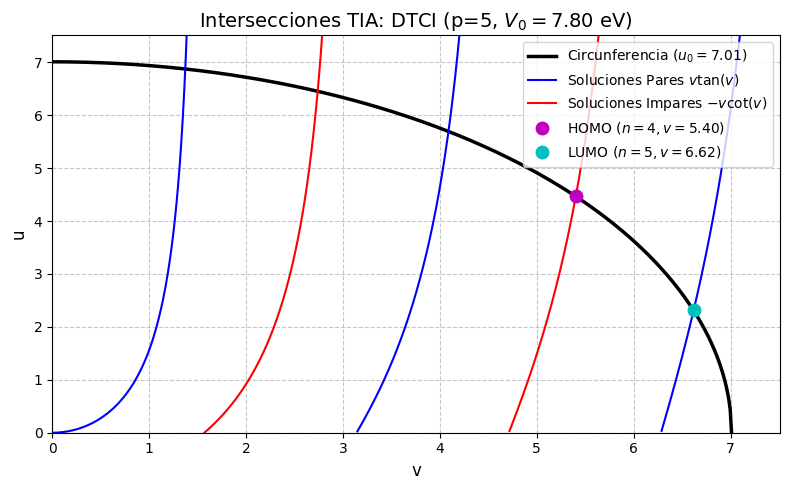

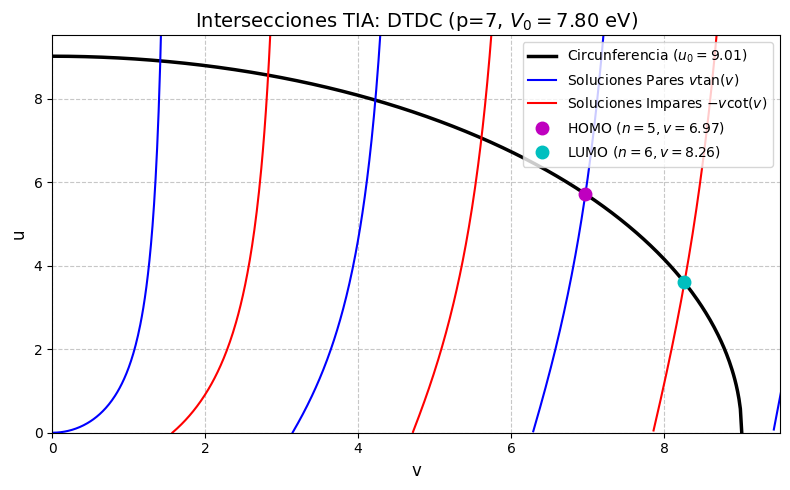

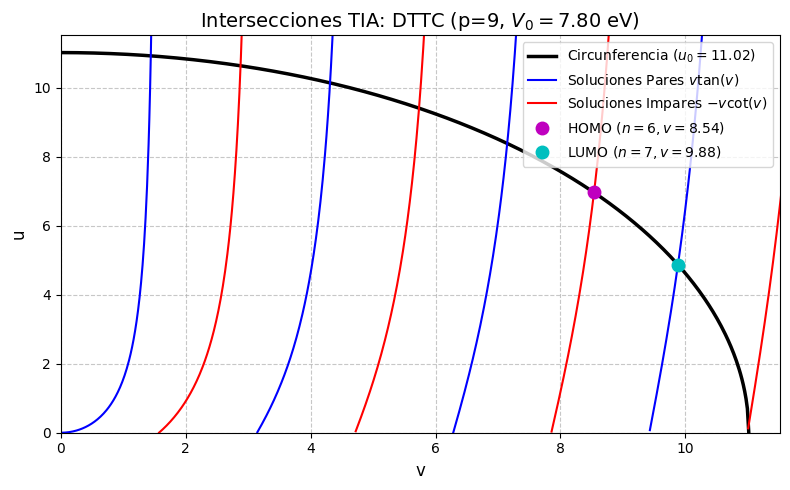

In [ ]:
# =========================================================
# 7. GRÁFICOS DE LAS INTERSECCIONES (u vs v) PARA LAS 3 TIA-CIANINAS
# =========================================================
# Diccionario para etiquetar los gráficos correctamente
nombres_tia = {5: 'DTCI', 7: 'DTDC', 9: 'DTTC'}
V0_fijo_tia = 7.80 # Valor predefinido para la familia TIA

# Iteramos sobre los tres valores de p (5, 7 y 9)
for p_val in p_exp:
    nombre = nombres_tia[p_val]
    a_val = (p_val + 2) * d
    V0_J = V0_fijo_tia * e_charge  # Usamos el V0 de 7.80 eV

    # Calculamos el radio exacto de la circunferencia para esta molécula
    u0_val = (a_val / 2) * np.sqrt(2 * m * V0_J) / hbar

    # Determinamos los niveles cuánticos correspondientes
    n_homo = int((p_val + 3) / 2)
    n_lumo = n_homo + 1

    # Encontramos los valores v exactos
    v_homo = encontrar_interseccion(n_homo, u0_val)
    v_lumo = encontrar_interseccion(n_lumo, u0_val)

    # --- PREPARACIÓN DE DATOS PARA EL GRÁFICO ---
    v_arr = np.linspace(0.01, u0_val + 1, 1000)

    # 1. Curva de la Circunferencia
    v_circ = np.linspace(0, u0_val, 500)
    u_circ = np.sqrt(u0_val**2 - v_circ**2)

    # 2. Soluciones Pares
    u_par = v_arr * np.tan(v_arr)
    u_par[(u_par < 0) | (u_par > u0_val + 2)] = np.nan

    # 3. Soluciones Impares
    u_impar = -v_arr / np.tan(v_arr)
    u_impar[(u_impar < 0) | (u_impar > u0_val + 2)] = np.nan

    # --- CREACIÓN DEL GRÁFICO INDIVIDUAL ---
    plt.figure(figsize=(8, 5))

    plt.plot(v_circ, u_circ, 'k-', linewidth=2.5, label=f'Circunferencia ($u_0 = {u0_val:.2f}$)')
    plt.plot(v_arr, u_par, 'b-', label='Soluciones Pares $v \\tan(v)$')
    plt.plot(v_arr, u_impar, 'r-', label='Soluciones Impares $-v \\cot(v)$')

    # Puntos de intersección
    if v_homo is not None:
        u_homo = np.sqrt(u0_val**2 - v_homo**2)
        plt.plot(v_homo, u_homo, 'mo', markersize=9, label=f'HOMO ($n={n_homo}, v={v_homo:.2f}$)')

    if v_lumo is not None:
        u_lumo = np.sqrt(u0_val**2 - v_lumo**2)
        plt.plot(v_lumo, u_lumo, 'co', markersize=9, label=f'LUMO ($n={n_lumo}, v={v_lumo:.2f}$)')

    # Formato
    plt.xlim(0, u0_val + 0.5)
    plt.ylim(0, u0_val + 0.5)
    plt.title(f'Intersecciones TIA: {nombre} (p={p_val}, $V_0={V0_fijo_tia:.2f}$ eV)', fontsize=14)
    plt.xlabel('v', fontsize=12)
    plt.ylabel('u', fontsize=12)
    plt.legend(fontsize=10, loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()

    plt.show()
